In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from scipy import stats
import smarts_cerebellum.globals as gl

cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_2024_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients
cerebel['hemisphere'] = cerebel.regionname.str[2]

# NORMALISE AFFECTED VOLUME BY UNAFFECTED VOLUME - CEREBELLUM (affected - contra i.e. left)
cerebel['regionname_bilat'] = cerebel.regionname.str[:2]
left_cerebel = cerebel[cerebel.hemisphere == 'L'][['subj_id', 'Week', 'region', 'regionname', 'regionname_bilat', 'mean']].rename(columns = {'mean': 'left_mean'})
right_cerebel = cerebel[cerebel.hemisphere == 'R'][['subj_id', 'Week', 'region', 'regionname', 'regionname_bilat', 'mean']].rename(columns = {'mean': 'right_mean'})
norm_cerebel = left_cerebel.merge(right_cerebel, on = ['subj_id', 'Week', 'regionname_bilat'], suffixes = ('_left', '_right'))

norm_cerebel['left_norm'] = norm_cerebel['left_mean']/norm_cerebel['right_mean']
cerebel = norm_cerebel


behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t') # only paretic hand
# behavioural data copied from smarts/bedside/analysis/

# make subj_id column consistent
behav['subj_id'] = behav['subj_name'].str.strip()
behav.loc[behav['week']==1, 'week'] = 0
behav.rename(columns = {'week': 'Week'}, inplace = True)

resid = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'piecewise_SI_residuals_week.tsv'), sep = '\t')

In [4]:
# INDIVIDUATION
rows_indiv = []
for roi in gl.rois['Nettekoven2024']:
    for week in gl.weeks:
        indiv_plot = behav[behav.Week == week]
        cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == roi)]
        cerebel_indiv = pd.merge(cerebel_plot, indiv_plot, on = ['subj_id', 'Week'], suffixes = ('_cerebel', '_indiv'))
        
        r_stat_indiv, p_val_indiv = stats.pearsonr(cerebel_indiv['left_norm'], cerebel_indiv['indiv_norm'])

        n = len(cerebel_indiv.subj_id.unique())
        z, se = np.arctanh(r_stat_indiv), 1/np.sqrt(n-3)
        lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
        rows_indiv.append({'Week': week, 'roi': roi, 'r_stat_indiv': r_stat_indiv, 'p_val_indiv': p_val_indiv, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
r_df_indiv = pd.DataFrame(rows_indiv)

In [5]:
# STRENGTH
rows_mvc = []
for roi in gl.rois['Nettekoven2024']:
    for week in gl.weeks:
        mvc_plot = behav[behav.Week == week]
        cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == roi)]
        cerebel_mvc = pd.merge(cerebel_plot, mvc_plot, on = ['subj_id', 'Week'], suffixes = ('_cerebel', '_mvc'))
        
        r_stat_mvc, p_val_mvc = stats.pearsonr(cerebel_mvc['left_norm'], cerebel_mvc['mvc_norm'])

        n = len(cerebel_mvc.subj_id.unique())
        z, se = np.arctanh(r_stat_mvc), 1/np.sqrt(n-3)
        lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
        
        rows_mvc.append({'Week': week, 'roi': roi, 'r_stat_mvc': r_stat_mvc, 'p_val_mvc': p_val_mvc, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
r_df_mvc = pd.DataFrame(
    rows_mvc)

In [6]:
# RESIDUALS
rows = []
for roi in gl.rois['Nettekoven2024']:
    for week in gl.weeks:
        resid_plot = resid[resid.Week == week]
        cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == roi)]
        cerebel_resid = pd.merge(cerebel_plot, resid_plot, on = ['subj_id', 'Week'], suffixes = ('_cerebel', '_resid'))
        
        r_stat_resid, p_val_resid = stats.pearsonr(cerebel_resid['left_norm'], cerebel_resid['y_hat']) # use fitted value from piecewise function, y_hat

        n = len(cerebel_resid.subj_id.unique())
        z, se = np.arctanh(r_stat_resid), 1/np.sqrt(n-3)
        lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
        rows.append({'Week': week, 'roi': roi, 'r_stat_resid': r_stat_resid, 'p_val_resid': p_val_resid, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
r_df_resid = pd.DataFrame(rows)

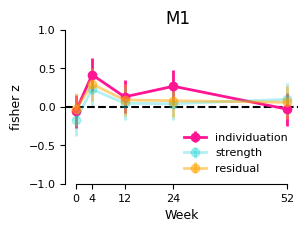

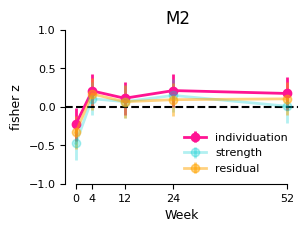

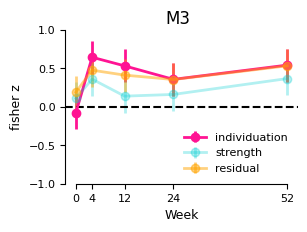

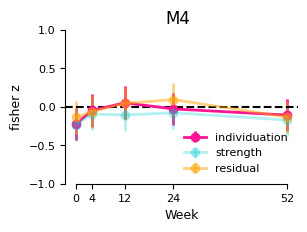

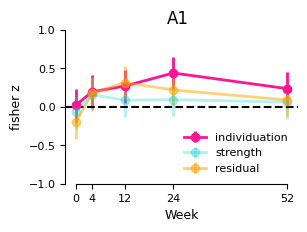

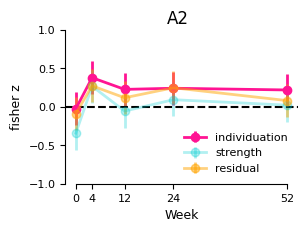

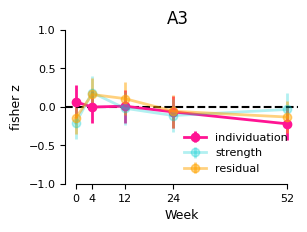

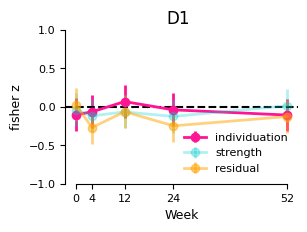

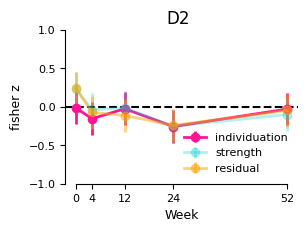

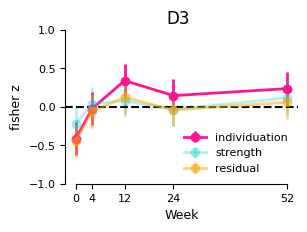

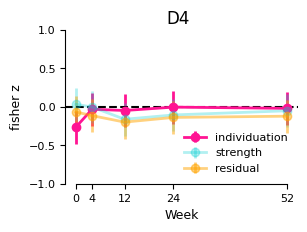

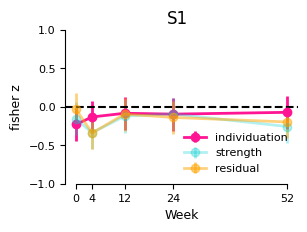

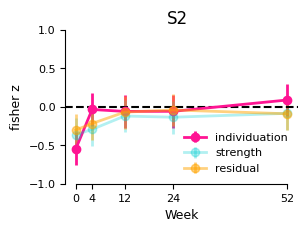

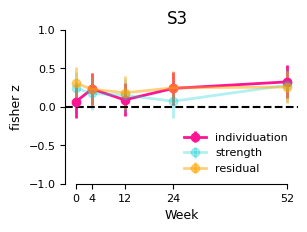

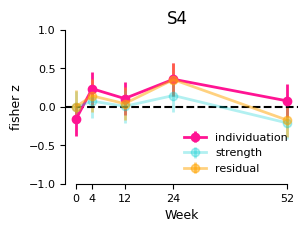

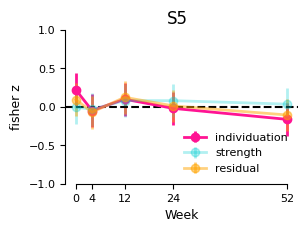

In [7]:
# plot r values for correlations

for roi in gl.rois['Nettekoven2024']:
    fig, ax = plt.subplots(figsize = (3,2))
    plotdf_indiv = r_df_indiv[r_df_indiv['roi'] == roi].sort_values('Week')
    plotdf_mvc = r_df_mvc[r_df_mvc['roi'] == roi].sort_values('Week')
    plotdf_resid = r_df_resid[r_df_resid['roi'] == roi].sort_values('Week')

    ax.errorbar(x = plotdf_indiv['Week'], y = plotdf_indiv['z'], yerr = se,              
    marker = 'o', linestyle = '-', linewidth = 2, color = 'deeppink', alpha = 1, label = 'individuation')

    ax.errorbar(x = plotdf_mvc['Week'], y = plotdf_mvc['z'], yerr = se,              
    marker = 'o', linestyle = '-', linewidth = 2, color = 'darkturquoise', alpha = .3, label = 'strength')

    ax.errorbar(x = plotdf_resid['Week'], y = plotdf_resid['z'], yerr = se,              
    marker = 'o', linestyle = '-', linewidth = 2, color = 'orange', alpha = .5, label = 'residual')

    ax.set_xticks(gl.weeks)
    ax.set_xlabel('Week')
    ax.set_ylabel('fisher z')
    ax.set_ylim(-1, 1)
    plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
    ax.legend(loc = 'lower right', frameon = False, fontsize = 8)
    fig.suptitle(roi)
    sns.despine(trim = True)
    plt.show()